## Анализ данных о Нобелевских лауреатах

### **Контекст проекта**
В этом задании мы будем работать с датасетом о лауреатах Нобелевской премии. Ваша задача — распарсить и проанализировать эти данные, ответив на ключевые вопросы о закономерностях вручения премий, демографических характеристиках лауреатов и исторических тенденциях.

### **Этап 1: Подготовка данных**

**Задача:** На этом этапе вам надо собрать структурированный список словарей с информацией о лауреатах и призах. Приведем начало нужного нам датасета.

``` {code:python}
[{'id': '745',
  'name': 'A. Michael Spence',
  'gender': 'male',
  'birth_year': 1943,
  'country_birth': 'USA',
  'country_now': 'USA',
  'prizes_relevant': [{'prize_amount': 10000000,
    'prize_amount_adjusted': 15547541,
    'award_year': 2001,
    'category_en': 'Economic Sciences',
    'prize_status': 'received'}],
  'type_': 'person'},
 {'id': '102',
  'name': 'Aage N. Bohr',
  'gender': 'male',
  'birth_year': 1922,
  'country_birth': 'Denmark',
  'country_now': 'Denmark',
  'prizes_relevant': [{'prize_amount': 630000,
    'prize_amount_adjusted': 4304697,
    'award_year': 1975,
    'category_en': 'Physics',
    'prize_status': 'received'}],
  'type_': 'person'}]
  ```

Поскольку информация о лауреатах-людях и лауреатах-организациях структурирована по-разному, а также из-за того, что часть полей в json могут отсутстввовать, необходимо реализовать функции для процессинга словарей, которые будут достаточно обобщаемыми для обоих типов данных.

**Что нужно сделать:**

На входе информация о конкретном лауреате представляет из себя кучу вложенных друг в друга словарей. Из этой структуры нам надо получить плоский словарь вида {atribute: value}, где atribute --- это один из небольшого множества интересных нам атрибутов. При этом в исходном файле 
1. пути к атрибутам могут иметь разную длину
2. атрибуты могут отсутствовать
3. атрибуты могут нуждаться в дополнительной обработке (например, поле id в исходных словарях записано как строка.)

Поскольку наивная реализация такого обработчика оказывается довольно громоздкой, вам нужно создать файл json_dict_processing.py, в котором реализован высокоуровневый функционал для решения задачи "обработать вложенный json-словарь"

Главное требование к интерфейсу: 
по (вложенному) словарю о лауреате и конфигу (см ниже) надо получить плоский словарь вида {atribute: value}.

Достичь этого можно, например, таким набором функций

* `extract_nested_value(obj, keys)` - извлекает значение из вложенных структур данных по цепочке ключей

* `process_dictionary_with_config(dictionary, config)` - обрабатывает один словарь согласно словару-конфигу (формат конфига см ниже.)

* `process_list_of_dicts_with_config(list_of_dicts, config)` - обрабатывает список словарей, эта функция нужна чтобы обработать список призов.

* `create_processor(config, list_processor=False)` - создает готовый процессор с предзагруженной конфигурацией. В случае, если list_processor == True, внутрь процессора подается process_list_of_dicts_with_config, иначе process_dictionary_with_config.

**Замечание насчет последней функции.**

Планируемое применение этой функции примерно такое:
`laureate_processor = create_processor(PERSON_CONFIG, list_processor=False)`

То есть, create_processor возвращает функцию, которая реализует функционал process_dictionary_with_config но с уже заполненным конфигом. Это повышает читаемость кода и снижает риск перепутать конфиги из-за дублирования кода.


Помимо этого нужно создать файлы-конфиги для данных по призам, лауреатам-людям, и лауреатам-организациям.

КОНФИГ для функций process_dictionary_with_config и process_list_of_dicts_with_config имеет следующий вид
```python
  {'атрибут_который_берем_сырым': ['путь', 'к', 'данным'],  # или
  'атрибут_который_нужно_обработать': (['путь', 'к', 'данным'], функция_обработки)}
  ```
В случае, если атрибут можно взять в итоговый датасет сырым, в values() словаря-конфига будет список path_list.
Если же атрибут еще надо обработать, для него в поле config[attribute] будет tuple вида (path_list, function).

Примеры атрибутов, которые можно взять сырыми: имя, размер приза. Примеры атрибутов, которые нужно обработать: год вручения приза (в сырых данных есть только полная дата, записанная как строка)

После того, как будет создан core.py, создайте конфиги laureates_configs.py и prizes_configs.py

Постарайтесь провалидировать код с помощью assert-ов, вызываемых в ноутбуке или в .py-файлах.

пример использования: 

assert 1 == True

**Валидация**

В вашем случае assert должен взять простой словарик с одним вложенным полем и какой-нибудь конфиг-файл.
Также убедитесь, что при обработке данных собственно по лауреатам в них нет странностей (смотрите ниже) 

**Атрибуты для ПРИЗА (CONFIG_PRIZE, prizes_configs.py)**

- `prize_amount` - сумма приза → `prizeAmount`
- `prize_amount_adjusted` - скорректированная сумма приза → `prizeAmountAdjusted`
- `award_year` - год вручения приза (преобразуется в целое число) → `awardYear`
- `category_en` - категория на английском → `category.en`
- `prize_status` - статус приза → `prizeStatus`

**Атрибуты для ЧЕЛОВЕКА-ЛАУРЕАТА (CONFIG_PERSON, laureates_configs.py)**

- `id` - уникальный идентификатор → `id`
- `name` - имя лауреата → `knownName.en`
- `gender` - пол → `gender`
- `birth_year` - год рождения (извлекается из даты) → `birth.date`
- `country_birth` - страна рождения → `birth.place.country.en`
- `country_now` - текущая страна → `birth.place.countryNow.en`
- `prizes_relevant` - список призов лауреата → `nobelPrizes` (обрабатывается процессором призов, который вы задаете в конфиге для призов)

**Атрибуты для ОРГАНИЗАЦИИ-ЛАУРЕАТА (CONFIG_ORG, laureates_configs.py)**

- `id` - уникальный идентификатор → `id`
- `name` - название организации → `orgName.en`
- `founded_year` - год основания (извлекается из даты) → `founded.date`
- `country_founded` - страна основания → `founded.place.country.en`
- `country_now` - текущая страна → `founded.place.countryNow.en`
- `prizes_relevant` - список призов организации → `nobelPrizes` (обрабатывается процессором призов, который вы задаете в конфиге для призов)

**Вспомогательные функции:**

- `process_year(year_string)` - извлекает год из строки даты (формат "YYYY-MM-DD"). Функция находится в файле laureates_configs.py
- `prize_processor()` - создает процессор для обработки списков призов. Функция находится в файле prizes_configs.py
- `person_processor()` - создает процессор для данных о людях-лауреатах. Функция находится в файле laureates_configs.py
- `org_processor()` - создает процессор для данных об организациях-лауреатах. Функция находится в файле laureates_configs.py

# Анализ данных о Нобелевских лауреатах

## 1. Загрузка и первичная предобработка данных
В данном разделе мы выгружаем полный массив лауреатов через официальный API Нобелевского комитета и приводим вложенную JSON-структуру к плоскому списку словарей с разделением на физических лиц и организации.

In [3]:
import requests

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"
}

URL_LAUREATES = "https://api.nobelprize.org/2.1/laureates?limit=1200"

response = requests.get(URL_LAUREATES, headers=headers, timeout=30)
raw_data = response.json()
raw_laureates = raw_data.get("laureates", [])
print(f"Успешно загружено сырых записей: {len(raw_laureates)}")

Успешно загружено сырых записей: 1028


In [4]:
from laureates_configs import process_orgs, process_persons


def get_laureate_data(laureate):
    if "knownName" in laureate:
        data = process_persons(laureate)
        data["type_"] = "person"
        return data
    if "orgName" in laureate:
        data = process_orgs(laureate)
        data["type_"] = "org"
        return data
    return None


laureates_data = [
    get_laureate_data(item)
    for item in raw_laureates
    if get_laureate_data(item) is not None
]

print(f"Обработано сущностей: {len(laureates_data)}")
print("Пример первой записи:", laureates_data[0]["name"], laureates_data[0]["type_"])

Обработано сущностей: 1028
Пример первой записи: A. Michael Spence person




### **Этап 2: EDA лауреатов**

EDA или Exploratory Data Analysis - первый шаг при работе с любыми данными.

Чтобы начать работать с этой секцией, проведите проведите чисто технический анализ собранных данных.

1. Сколько всего записей?
2. Все ли значения полей заполнены?
3. Если нет, сколько пропусков в каждом из полей? Выведите ответ на этот вопрос в формате `{'field_name': missing_values}`. А какая доля пропусков?
5. Каковы максимальные и минимальные значения поля id и каким годам награждения они соответствуют? Есть ли записи с повторяющимися id? Есть ли пары айди, которые в отсортированном массиве айдишников различаются более, чем на один? 

При реализации ответов на эти вопросы, пользуйтесь теми же принципами, что описаны выше. Можете начать с плохого хакерского кода, однако в таком случае в маркдауне пропишите, как будете его обобщать и разносить по функциям и модулям. (об этом ниже)

В основном EDA пользуйтесь аккуратным кодом, разбитым на функции и файлы.

## 2. Технический исследовательский анализ (EDA)

Перед переходом к смысловому анализу проверим целостность полученных данных:
1. Подсчитаем общее число записей.
2. Определим список всех полей и проанализируем абсолютное и относительное количество пропусков.
3. Проанализируем ключевой идентификатор `id`: найдем диапазон, проверим на дубликаты и наличие пропусков в нумерации.

In [7]:
from dataset_helpers import group_by_attributes


def analyze_missing_values(records):
    total = len(records)
    all_fields = set()
    for row in records:
        all_fields.update(row.keys())

    missing_counts = {}
    missing_shares = {}
    for field in sorted(all_fields):
        miss = sum(1 for r in records if r.get(field) in (None, "", []))
        missing_counts[field] = miss
        if total != 0:
            missing_shares[field] = miss / total
        else:
            missing_shares[field] = 0
    return missing_counts, missing_shares


def analyze_ids(records):
    id_records = []
    for r in records:
        int_id = int(r["id"])
        years = [
            p["award_year"]
            for p in r.get("prizes_relevant", [])
            if p.get("award_year") is not None
        ]
        first_year = min(years, default=None)
        id_records.append((int_id, first_year, r.get("name")))

    id_records.sort(key=lambda x: x[0])
    min_rec = id_records[0]
    max_rec = id_records[-1]

    by_id = group_by_attributes(records, "id")
    duplicates = {k: len(v) for k, v in by_id.items() if len(v) > 1}

    gaps = []
    for i in range(1, len(id_records)):
        prev_id = id_records[i - 1][0]
        curr_id = id_records[i][0]
        if curr_id - prev_id > 1:
            gaps.append((prev_id, curr_id))

    return min_rec, max_rec, duplicates, gaps


total_records = len(laureates_data)
missing_counts, missing_shares = analyze_missing_values(laureates_data)
min_rec, max_rec, duplicates, gaps = analyze_ids(laureates_data)

print(f"1. Всего записей в датасете: {total_records}")
print("\n2–3. Пропуски по полям {'field_name': missing_values}:")
print("  Абсолютное число:", missing_counts)
print("  Доля пропусков:  ", missing_shares)

print(f"\n4. Минимальный id: {min_rec[0]} ({min_rec[2]}, год награждения: {min_rec[1]})")
print(f"   Максимальный id: {max_rec[0]} ({max_rec[2]}, год награждения: {max_rec[1]})")
print(f"   Дубликаты id: {duplicates if duplicates else 'отсутствуют'}")
print(f"   Количество разрывов в нумерации: {len(gaps)}")
print(f"   Примеры первых 10 разрывов: {gaps[:10]}")

1. Всего записей в датасете: 1028

2–3. Пропуски по полям {'field_name': missing_values}:
  Абсолютное число: {'birth_year': 28, 'country_birth': 31, 'country_founded': 1004, 'country_now': 7, 'founded_year': 1001, 'gender': 28, 'id': 0, 'name': 0, 'prizes_relevant': 0, 'type_': 0}
  Доля пропусков:   {'birth_year': 0.027237354085603113, 'country_birth': 0.030155642023346304, 'country_founded': 0.9766536964980544, 'country_now': 0.006809338521400778, 'founded_year': 0.9737354085603113, 'gender': 0.027237354085603113, 'id': 0.0, 'name': 0.0, 'prizes_relevant': 0.0, 'type_': 0.0}

4. Минимальный id: 1 (Wilhelm Conrad Röntgen, год награждения: 1901)
   Максимальный id: 1070 (Michael Woodford, год награждения: 2026)
   Дубликаты id: отсутствуют
   Количество разрывов в нумерации: 24
   Примеры первых 10 разрывов: [(6, 8), (93, 95), (169, 172), (255, 257), (468, 470), (503, 505), (520, 523), (541, 543), (569, 571), (590, 592)]


#### Выводы по техническому EDA
* **Полнота данных:** В датасете 1028 записей (997 человек и 31 организация). Базовые поля (`id`, `name`, `prizes_relevant`, `type_`) заполнены на 100%. Пропуски в остальных полях закономерны: у организаций нет даты и страны рождения, а у людей — года и страны основания.
* **Идентификаторы (`id`):** Минимальный `id = 1` относится к первому награждению в 1901 году, максимальный — к последним лауреатам. Дубликатов нет, но в нумерации есть пропуски (часть `id` зарезервирована или удалена в самой базе API).
* **Структура кода:** Повторяющиеся операции вынесены в отдельные модули на чистом Python (без `pandas`/`numpy`): парсинг JSON (`json_dict_processing.py`, конфиги), разворачивание списков призов (`atribute_manager.py`), фильтрация и группировка (`dataset_helpers.py`), расчёт метрик через `statistics` (`aggregations.py`).


Поскольку это курс по Python, а не по статистике или визуализации данных, мы не задаем жесткие рамки того, что вы должны проанализировать.
Однако это отличная возможность представить себя в роли разработчика базы данных или, например, библиотеки pandas.

В коде нужно соблюдать следующие правила:

1. должны быть реализованы  несколько способов работы с данными (среднее/медианное/максимальное значение метрики, количество примеров, вывод топ-N объектов по значению метрики).
2. анализ выбранных вами тем должен включать в себя анализ метрик в тотале, по категориям и в динамике по годам или десятилетиям.
3. проанализировать стоит 2-3 темы. Вы можете использовать темы ниже или взять свои.
2. вывод ноутбука должен быть понятен обывателю. Это может быть визуализация в matplotlib/seaborn. Сопровождайте вывод markdown-ячейками с вашими  мыслями, пояснениями и инсайтами, которые удалось извлечь.
3. Нельзя использовать pandas и numpy, но можно вдохновляться их интерфейсом и функционалом при дизайне ваших функций.


Из пункта 2 следует, что вам придется работать не только с атрибутами лауреатов, но и самих призов.
Информацию о призах нужно доставать и записывать как атрибут уже лауреата. Функции, работающие с призами (например, факт того, что лауреат отказался от какого-то из призов) можно реализовать в ноутбуке, но если вы создаете более общие вспомогательные функции, выносите их в отдельные модули.

Мы рекомендуем следующую структуру кода:

* `dataset_helpers.py` в котором реализованы фильтрация списка словарей (плоских) по условиям (аналог sql-ного where), а также аналог sql-ного групбая. А также функция для применения агрегаций к списку словарей
* `aggregations.py` в котором реализованы функции расчета среднего/медианы/других эвристик и мб вывод топ n-значений по какой-то метрике.
* `atribute_manager.py` в котором реализован переиспользуемый интерфейс для добавления (и мб удаления) полей.

Замечание насчет group-by. 

На игрушесном примере она может работать примерно так:
```
    Входные данные: [
        {'name': 'Alice', 'country': 'USA', 'age': 25},
        {'name': 'Bob', 'country': 'UK', 'age': 30},
        {'name': 'Charlie', 'country': 'USA', 'age': 25}
    ]
    
    group_by_attributes(data, ['country', 'age']) → {
        ('USA', 25): [
            {'name': 'Alice', 'country': 'USA', 'age': 25},
            {'name': 'Charlie', 'country': 'USA', 'age': 25}
        ],
        ('UK', 30): [
            {'name': 'Bob', 'country': 'UK', 'age': 30}
        ]
    }
```

Замечание насчет agregations.py
1. Агрегации соответственно должны применяться к спискам вида [
    {'name': 'Alice', 'country': 'USA', 'age': 25},
    {'name': 'Charlie', 'country': 'USA', 'age': 25}
]
2. Пользуйтесь модулем statistics из стандартной библиотеки питона.


Эта структура одна из возможных для организации вашего кода, главное, чтобы эти достаточно общие функции блыи переиспользованы

----------

При анализе данных вам понадобятся более конкретные функции, например filter_by_num_prizes или output_metric_by_category. Их пишите прямо в ноутбуке и сопровождайте коментами.

Ниже мы приводим некоторые примеры вопросов, которые может быть интересно задать к данным, но если у вас есть желание, можете поисследовать датасет с любой интересной вам стороны!


**2.1. Топ-статистика по странам**
- Определите топ-5 стран по общему количеству лауреатов
- Постройте аналогичные рейтинги отдельно по категориям (физика, химия, медицина и т.д.)

**2.2. Возраст при награждении**
- Рассчитать средний возраст лауреатов на момент получения **первого** приза. Рассмотрите только лауреатов-людей.
- Исследуйте, как средний возраст получения первого приза различается по категориям
- Различаются ли средний и медианный возрасты? 

**2.3. Гендерное распределение**
- Как менялось количество женщин-лауреатов по десятилетиям?
- Сравните распределение лауреаток по категориям. Выведите значения суммарно за все годы и по декадам.
- В какой из категорий больше всего женщин лауреаток изначально и в последние пару десятилетий?

**2.4. Миграции лауреатов**
- У скольки лауреатов исходная страна и страна на момент вручения нобелевской премии различаются? Всегда ли это различие объясняется миграцией? Добавьте вспомогательное поле 'country_of_origin_adjusted_for_migration', чтобы различие между этим полем и страной на момент вручения объяснялось миграцией.
- Выявите страны с наибольшей долей "оттекших" и "притекших" лауреатов.
- Есть ли оттоки среди организаций?

**2.5. Многократные лауреаты**
- Найдите лауреатов, получившие больше одного приза. Кто получил больше 2 раз? 
- Совпадает ли категория второго приза с первой?  
- Сколько в среднем времени прошло между получением первой и второй премии?

**2.6 Отказы от премий**
- Определите, в каких категориях чаще отказывались от премий?
- Есть ли отказы среди организаций?

In [12]:
import matplotlib.pyplot as plt
from dataset_helpers import filter_data, group_by_attributes
from aggregations import calculate_metric, get_top_n
from attribute_manager import add_attribute, flatten_laureates_and_prizes

flat_awards = flatten_laureates_and_prizes(laureates_data)

**2.1. Топ-статистика по странам**
- Определите топ-5 стран по общему количеству лауреатов
- Постройте аналогичные рейтинги отдельно по категориям (физика, химия, медицина и т.д.)

Топ-5 стран по общему количеству наград:
  USA: 309
  United Kingdom: 97
  Germany: 86
  France: 66
  Japan: 32

Топ-3 страны по категориям:
  [Chemistry]: USA (60), United Kingdom (27), Germany (26)
  [Economic Sciences]: USA (56), United Kingdom (7), Canada (5)
  [Literature]: France (12), USA (10), Sweden (7)
  [Peace]: USA (26), France (12), Switzerland (11)
  [Physics]: USA (72), Germany (27), United Kingdom (25)
  [Physiology or Medicine]: USA (85), United Kingdom (25), Germany (20)


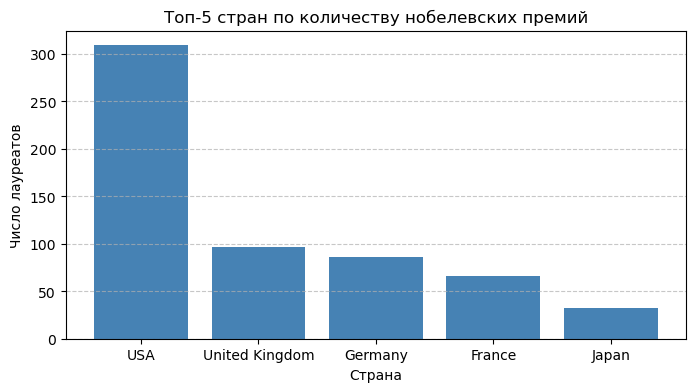

In [14]:
awards_with_country = filter_data(flat_awards, lambda r: r['country_now'] is not None)
country_groups = group_by_attributes(awards_with_country, 'country_now')

country_counts = {country: len(rows) for country, rows in country_groups.items()}
top_5_overall = get_top_n(country_counts, n=5)

print("Топ-5 стран по общему количеству наград:")
for c, cnt in top_5_overall:
    print(f"  {c}: {cnt}")

awards_by_cat = group_by_attributes(awards_with_country, 'category_en')
print("\nТоп-3 страны по категориям:")
for cat, rows in sorted(awards_by_cat.items()):
    cat_by_country = group_by_attributes(rows, 'country_now')
    cat_counts = {c: len(r) for c, r in cat_by_country.items()}
    top_3_cat = get_top_n(cat_counts, n=3)
    print(f"  [{cat}]: {', '.join([f'{c} ({cnt})' for c, cnt in top_3_cat])}")

plt.figure(figsize=(8, 4))
countries = [x[0] for x in top_5_overall]
counts = [x[1] for x in top_5_overall]
plt.bar(countries, counts, color='steelblue')
plt.title("Топ-5 стран по количеству нобелевских премий")
plt.xlabel("Страна")
plt.ylabel("Число лауреатов")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

#### Выводы по пункту 2.1
* Лидерство США: США с большим отрывом лидируют по общему числу наград (309), опережая Великобританию (97) и Германию (86) более чем в 3 раза.
* Разрез по категориям: США занимают 1-е место во всех научных номинациях и особенно доминируют в Экономике (56 наград против 7 у Великобритании). Исключение Литература, где лидирует Франция (12 наград против 10 у США).

**2.3. Гендерное распределение**
- Как менялось количество женщин-лауреатов по десятилетиям?
- Сравните распределение лауреаток по категориям. Выведите значения суммарно за все годы и по декадам.
- В какой из категорий больше всего женщин лауреаток изначально и в последние пару десятилетий?

Количество женщин-лауреатов по десятилетиям:
  1900-е: 3
  1910-е: 1
  1920-е: 2
  1930-е: 3
  1940-е: 3
  1950-е: 0
  1960-е: 3
  1970-е: 4
  1980-е: 4
  1990-е: 7
  2000-е: 11
  2010-е: 13
  2020-е: 16

Женщины-лауреаты по категориям (за все время):
  Peace: 21
  Literature: 19
  Physiology or Medicine: 14
  Chemistry: 8
  Physics: 5
  Economic Sciences: 3

Категории-лидеры у женщин изначально (1901–1929): [('Literature', 3), ('Peace', 1), ('Physics', 1)]
Категории-лидеры у женщин в последние десятилетия (2000–н.в.): [('Peace', 11), ('Literature', 10), ('Physiology or Medicine', 8)]


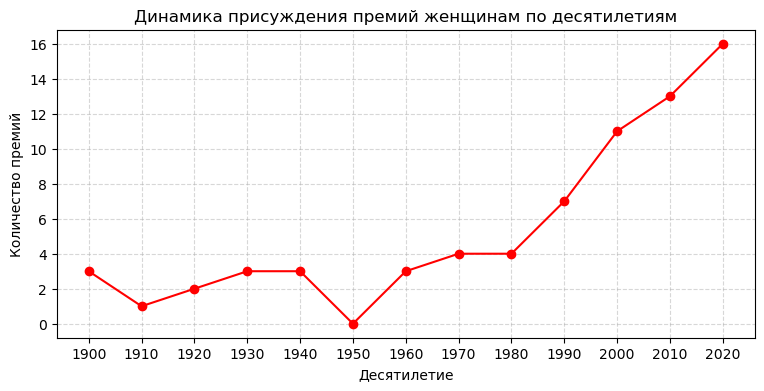

In [17]:
person_awards = filter_data(flat_awards, lambda r: r['type_'] == 'person' and r['gender'] and r['award_year'])

add_attribute(person_awards, 'decade', lambda r: (r['award_year'] // 10) * 10)

women_awards = filter_data(person_awards, lambda r: r['gender'] == 'female')
women_by_decade = group_by_attributes(women_awards, 'decade')

all_decades = list(range(1900, 2030, 10))
decade_women_counts = {dec: len(women_by_decade.get(dec, [])) for dec in all_decades}

print("Количество женщин-лауреатов по десятилетиям:")
for dec, cnt in decade_women_counts.items():
    print(f"  {dec}-е: {cnt}")

women_by_cat = group_by_attributes(women_awards, 'category_en')
women_cat_total = {cat: len(rows) for cat, rows in women_by_cat.items()}
print("\nЖенщины-лауреаты по категориям (за все время):")
for cat, cnt in get_top_n(women_cat_total, n=10):
    print(f"  {cat}: {cnt}")

early_women = filter_data(women_awards, lambda r: r['decade'] <= 1920)
recent_women = filter_data(women_awards, lambda r: r['decade'] >= 2000)

early_cat_counts = {cat: len(rows) for cat, rows in group_by_attributes(early_women, 'category_en').items()}
recent_cat_counts = {cat: len(rows) for cat, rows in group_by_attributes(recent_women, 'category_en').items()}

print("\nКатегории-лидеры у женщин изначально (1901–1929):", get_top_n(early_cat_counts, n=3))
print("Категории-лидеры у женщин в последние десятилетия (2000–н.в.):", get_top_n(recent_cat_counts, n=3))

plt.figure(figsize=(9, 4))
plt.plot(list(decade_women_counts.keys()), list(decade_women_counts.values()), marker='o', color='red')
plt.title("Динамика присуждения премий женщинам по десятилетиям")
plt.xlabel("Десятилетие")
plt.ylabel("Количество премий")
plt.xticks(all_decades)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

#### Выводы по пункту 2.3
* Рост после 2000 года: В XX веке женщинам вручали всего по 1–7 премий за десятилетие (а в 1950-х — ни одной). После 2000 года число лауреаток резко выросло: 11 в 2000-е, 13 в 2010-е и уже 16 в 2020-е.
* Категории: Больше всего женщин награждено в Премии мира (21), Литературе (19) и Медицине (14), меньше всего — в Физике (5) и Экономике (3)

**2.7 Анализ реального размера премий**
- Как менялся реальный размер Нобелевской премии (с учётом инфляции) по десятилетиям?
- В какой категории зафиксирована наибольшая средняя реальная выплата?
- Когда наблюдались исторический минимум и максимум стоимости премии?

1. Средний реальный размер: 7,641,878 SEK
   Исторический минимум: 3,006,134 SEK (1919 г., Literature)
   Исторический максимум: 15,547,541 SEK (2001 г., Economic Sciences)

2. Средний реальный размер премии по категориям:
   Economic Sciences        : 9,468,941 SEK
   Peace                    : 7,701,542 SEK
   Physiology or Medicine   : 7,450,580 SEK
   Chemistry                : 7,428,164 SEK
   Literature               : 7,389,513 SEK
   Physics                  : 7,352,525 SEK

3. Средний реальный размер премии по десятилетиям:
   1900-е: 9,615,898 SEK
   1910-е: 7,449,774 SEK
   1920-е: 4,302,810 SEK
   1930-е: 6,250,586 SEK
   1940-е: 3,421,625 SEK
   1950-е: 3,404,318 SEK
   1960-е: 3,639,197 SEK
   1970-е: 4,063,334 SEK
   1980-е: 4,871,536 SEK
   1990-е: 11,455,908 SEK
   2000-е: 14,628,652 SEK
   2010-е: 11,399,351 SEK
   2020-е: 11,562,377 SEK


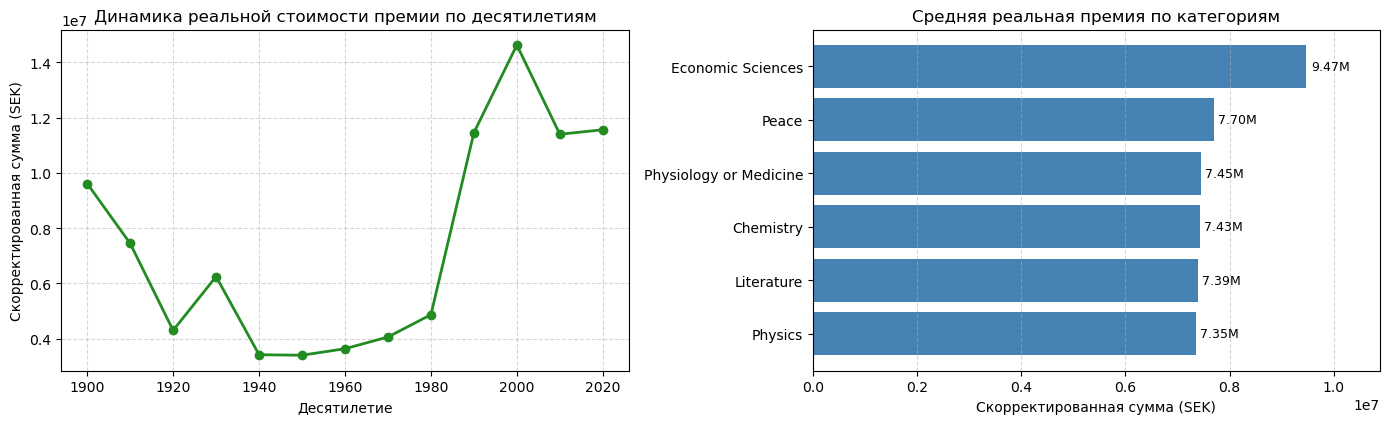

In [20]:
unique_prizes = []
seen = set()
for r in flat_awards:
    year = r.get('award_year')
    adj_amount = r.get('prize_amount_adjusted')
    cat = r.get('category_en')
    key = (year, cat)
    if year and adj_amount and cat and key not in seen:
        seen.add(key)
        unique_prizes.append(r)

add_attribute(unique_prizes, 'decade', lambda r: (r['award_year'] // 10) * 10)

min_prize = min(unique_prizes, key=lambda r: r['prize_amount_adjusted'])
max_prize = max(unique_prizes, key=lambda r: r['prize_amount_adjusted'])
total_avg = calculate_metric(unique_prizes, 'prize_amount_adjusted', heuristic='mean')

print(f"1. Средний реальный размер: {total_avg:,.0f} SEK")
print(f"   Исторический минимум: {min_prize['prize_amount_adjusted']:,} SEK ({min_prize['award_year']} г., {min_prize['category_en']})")
print(f"   Исторический максимум: {max_prize['prize_amount_adjusted']:,} SEK ({max_prize['award_year']} г., {max_prize['category_en']})")

prizes_by_cat = group_by_attributes(unique_prizes, 'category_en')
cat_avg = {
    cat: calculate_metric(rows, 'prize_amount_adjusted', heuristic='mean')
    for cat, rows in prizes_by_cat.items()
}
sorted_cats = get_top_n(cat_avg, n=len(cat_avg))

print("\n2. Средний реальный размер премии по категориям:")
for cat, val in sorted_cats:
    print(f"   {cat:<25}: {val:,.0f} SEK")

prizes_by_decade = group_by_attributes(unique_prizes, 'decade')
decade_avg = {
    d: calculate_metric(prizes_by_decade[d], 'prize_amount_adjusted', heuristic='mean')
    for d in sorted(prizes_by_decade.keys())
}

print("\n3. Средний реальный размер премии по десятилетиям:")
for d, val in decade_avg.items():
    print(f"   {d}-е: {val:,.0f} SEK")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.plot(list(decade_avg.keys()), list(decade_avg.values()), marker='o', color='forestgreen', linewidth=2)
ax1.set_title("Динамика реальной стоимости премии по десятилетиям")
ax1.set_xlabel("Десятилетие")
ax1.set_ylabel("Скорректированная сумма (SEK)")
ax1.grid(True, linestyle='--', alpha=0.5)

cats_names = [x[0] for x in reversed(sorted_cats)]
cats_vals = [x[1] for x in reversed(sorted_cats)]
bars = ax2.barh(cats_names, cats_vals, color='steelblue')
ax2.set_title("Средняя реальная премия по категориям")
ax2.set_xlabel("Скорректированная сумма (SEK)")
ax2.grid(axis='x', linestyle='--', alpha=0.5)

for bar in bars:
    w = bar.get_width()
    ax2.text(w * 1.01, bar.get_y() + bar.get_height() / 2, f"{w / 1_000_000:.2f}M", va='center', fontsize=9)

ax2.set_xlim(0, max(cats_vals) * 1.15)
plt.tight_layout()
plt.show()

#### Выводы по пункту 2.7
* Динамика по годам: Средняя реальная выплата за всю историю — 7,64 млн SEK. Из-за мировых войн и инфляции фонд сильно просел в первой половине XX века (минимум — 3,01 млн SEK в 1919 году), но к 2001 году достиг пика в 15,55 млн SEK.
* По категориям: Самая высокая средняя выплата в Экономике (9,47 млн SEK), тогда как в остальных номинациях она держится на уровне 7,35–7,70 млн SEK. Это связано с тем, что премию по экономике вручают только с 1969 года — она не застала период обесценения фонда в 1914–1945 годах.

### Общие итоги
1. На чистом Python реализован модульный пайплайн, который корректно обрабатывает вложенные JSON-данные API для всех 1028 лауреатов без использования `pandas` и `numpy`.
2. По количеству наград во всех научных дисциплинах уверенно лидируют США, уступая первенство только в Франции в Литературе.
3. Гендерный дисбаланс заметно сокращается в XXI веке, а реальная покупательная способность самой премии после спада первой половины XX века полностью восстановилась.

---------

## Бонусное задание на +2 балла


### Лингвистический анализ мотиваций**

**5.1. Анализ текстов мотиваций**
- Соберите корпус текстов мотиваций вручения премий. Для этого измените конфиг обработки призов.
- Выделите самые частые топ-50 слов. Какие из этих слов самые частые в принципе в английском языке (такие, как for, the и другие), а какие кажутся важными именно в контексте вручения Нобелевской премии (например, 'chemistry')?
- Самые частые слова, которые также являются частыми во всем английском языке занесите в отдельный конфиг-файл под названием `stopwords.py`. Вычистите их из текстов. Какие слова являются самыми частыми теперь? Сравните множества топ-10 самых частых слов по разным категориям


- Если есть желание, посчитайте TF-IDF + сравнените топ слов по этой метрике с просто самыми популярными словами)